# 09 · Fragen an die Daten

**NHyDB-0.27.1-Notebook-Reihe · v1**

NHyDB adressiert Daten mathematisch – trotzdem kannst du vertraute Fragen stellen: Filter, Bereiche, Gruppen, Textsuche und SQL. Dieses Notebook stellt **dieselben Fragen auf drei Wegen** (direkter Zugriff, die QueryEngine mit dem `Q`-Builder und NHySQL) und endet mit Abfragen, die nur eine Dynadron-Datenbank beantworten kann: Fragen über **Zahlen**.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* wann du gar keine Abfrage brauchst: Lesen über eine bekannte Adresse
* die QueryEngine: `Q`-Ausdrücke, Rückgabemodi, Sortierung und Aggregation
* NHySQL: nur lesendes `SELECT` mit Parametern, `GROUP BY`, Volltext und NumPy-Ausgabe
* wie `explain` zeigt, ob ein Scan oder ein Index eine Frage beantwortet
* Math-Provider: Abfragen über Folgen von Zellzahlen `N` und über Formeln

**Vorher empfohlen:** [02](02_from_address_to_data_v1.ipynb); [08](08_addresses_are_not_indexes_v1.ipynb) erklärt Indizes ausführlich.

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_address_grid(ax, u_max, v_max, lane, highlight=(), annotate=True, title=None, values=None):
    """The (u, v) plane of realm 1 for one lane; every square shows its number N.

    Anti-diagonals u + v = G are the groups. ``highlight`` is a set of (u, v);
    ``values`` maps (u, v) to a short text shown under N (stored data).
    """
    import matplotlib.colors as mcolors
    base = COLORS[lane]
    cmap = mcolors.LinearSegmentedColormap.from_list(lane, ["#ffffff", base])
    highlight = set(highlight)
    g_top = u_max + v_max
    for u in range(1, u_max + 1):
        for v in range(1, v_max + 1):
            n = nhydb.dynadron_n(1, u, v, lane)
            g = u + v
            shade = 0.25 + 0.6 * (g - 2) / max(1, g_top - 2)
            ax.add_patch(Rectangle((u - 0.5, v - 0.5), 1, 1, facecolor=cmap(shade),
                                   edgecolor=COLORS["attention"] if (u, v) in highlight else "white",
                                   linewidth=2.6 if (u, v) in highlight else 0.8, zorder=2 if (u, v) in highlight else 1))
            if annotate:
                txt = str(n)
                if values and (u, v) in values:
                    txt += "\n" + str(values[(u, v)])
                ax.text(u, v, txt, ha="center", va="center", fontsize=7.5 if n < 1000 else 6.5,
                        color="white" if shade > 0.55 else "#111827", zorder=3)
    for g in range(2, g_top + 1):        # group diagonals u + v = G
        ax.plot([g - v_max - 0.5, g - 0.5], [v_max + 0.5, 0.5], color="#94a3b8", lw=0.4, zorder=0)
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.set_aspect("equal")
    ax.set_title(title or f"lane {lane}:  N = G² {'−' if lane == 'NL' else '+'} {'u' if lane == 'NL' else 'v'}",
                 color=base)


def plot_number_line(ax, start, stop, per_row=25, highlight=(), title=None):
    """The numbers start … stop−1 in reading order, coloured by what they are."""
    highlight = set(highlight)
    numbers = list(range(start, stop))
    rows = (len(numbers) + per_row - 1) // per_row
    for i, n in enumerate(numbers):
        x, y = i % per_row, -(i // per_row)
        k = kind_of(n)
        ax.add_patch(Rectangle((x - 0.46, y - 0.42), 0.92, 0.84, facecolor=COLORS[k],
                               edgecolor=COLORS["attention"] if n in highlight else "white",
                               linewidth=2.6 if n in highlight else 0.5))
        ax.text(x, y, str(n), ha="center", va="center", color="white", fontsize=7, fontweight="bold")
    ax.set_xlim(-0.7, per_row - 0.3)
    ax.set_ylim(-rows + 0.3, 0.7)
    ax.axis("off")
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("NL", "NR", "GZ", "N0")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("NL", "NR", "GZ", "N0")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)

import random

import numpy as np
import pandas as pd
from nhydb.query import Q, QueryEngine, expr_from_spec

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Hintergrund: drei Wege zu fragen

| Weg | Du schreibst | Gut für |
|---|---|---|
| **Direkter Zugriff** (Schicht A) | `db.get(realm, u)`, `db.get_n(N)`, `db.range(...)` | du weißt schon, *wo* die Daten liegen |
| **QueryEngine** (`Q`-Builder) | `Q.field("temp") > 20` | Abfragen, die in Python-Code gebaut werden |
| **NHySQL** | `SELECT … FROM … WHERE …` | vertraute Syntax, nur lesend |

QueryEngine und NHySQL teilen sich eine Engine: denselben Planer, dieselben Indizes, dieselben
Ergebnisse. NHySQL ist **nur lesend** – geschrieben wird über die Python-API.

## 1 · Ein kleiner Datenbestand: Wetterbeobachtungen

**Frage:** Was fragen wir ab? 60 Beobachtungen von 12 Stationen in vier Regionen, jede mit einer
Temperatur, einer Luftfeuchte und einem kurzen Textbericht. Ein CLASSIC-Layout, Datensatz = `u`.

In [2]:
STATIONS = [("Oslo", "north"), ("Tromsø", "north"), ("Helsinki", "north"),
            ("Lisbon", "south"), ("Seville", "south"), ("Naples", "south"),
            ("Dublin", "west"), ("Brest", "west"), ("Porto", "west"),
            ("Vienna", "east"), ("Krakow", "east"), ("Sofia", "east")]
BASE_TEMP = {"north": 4.0, "south": 19.0, "west": 12.0, "east": 9.0}
WEATHER = ["sunny and calm", "light rain", "heavy rain with strong wind", "fog in the morning",
           "clear sky", "snow showers", "strong wind from the sea", "thunderstorm in the evening"]

rng = random.Random(7)
rows = []
for i in range(60):
    city, region = STATIONS[i % len(STATIONS)]
    temp = round(BASE_TEMP[region] + rng.uniform(-6, 6), 1)
    weather = WEATHER[rng.randrange(len(WEATHER))]
    if region == "north" and temp < 2:
        weather = "snow showers"
    rows.append([i + 1, city, region, temp, rng.randrange(35, 98), f"{city}: {weather}"])

PATH = db_path("weather.nhydb")
with nhydb.create(PATH) as db:
    db.create_realm(1, "weather")
    db.create_shape(1, 1, "observation", [
        {"v": 1, "name": "id",       "type": "varuint"},
        {"v": 2, "name": "city",     "type": "utf8"},
        {"v": 3, "name": "region",   "type": "utf8"},
        {"v": 4, "name": "temp",     "type": "f64"},
        {"v": 5, "name": "humidity", "type": "u8"},
        {"v": 6, "name": "report",   "type": "utf8"},
    ])
    db.create_classic_layout(1, 1, "observations", shape_id=1)
    db.put_dense_batch(1, 1, rows, shape_id=1)

data = pd.DataFrame(rows, columns=["id", "city", "region", "temp", "humidity", "report"])
data.head(6)

,id,city,region,temp,humidity,report
0,1,Oslo,north,1.9,60,Oslo: snow showers
1,2,Tromsø,north,5.8,87,Tromsø: light rain
2,3,Helsinki,north,4.4,72,Helsinki: snow showers
3,4,Lisbon,south,13.7,37,Lisbon: fog in the morning
4,5,Seville,south,14.0,39,Seville: strong wind from the sea
5,6,Naples,south,15.9,38,Naples: strong wind from the sea


## 2 · Keine Abfrage nötig: Du kennst die Adresse

**Frage:** Was ist Beobachtung 17?

Wenn die Anwendung den Datensatz kennt (`u = 17`), gibt es nichts zu suchen: Die Zellzahlen
werden berechnet, die Engine liest den Datensatz direkt. Ein **Bereich** von Datensätzen ist
genauso direkt.

In [3]:
with nhydb.open(PATH) as db:
    rec = db.get(1, 17)
    print({k: v for k, v in rec.items() if not k.startswith("_")})
    print("record number N of observation 17:", db.record_anchor(1, 17)["N_ref"])
    some = [r["city"] for r in db.range(1, 20, 24)]                       # u = 20 … 24
    print("observations 20–24:", some)
    picked = list(db.select(1, 30, 32, ["city", "temp"]))                 # selected fields only
    print(pd.DataFrame(picked))
assert rec["id"] == 17 and len(some) == 5

{'id': 17, 'city': 'Seville', 'region': 'south', 'temp': 16.8, 'humidity': 58, 'report': 'Seville: thunderstorm in the evening'}
record number N of observation 17: N307
observations 20–24: ['Brest', 'Porto', 'Vienna', 'Krakow', 'Sofia']
   _u  _lane _lane_name    city  temp
0  30      0         NL  Naples  21.4
1  31      0         NL  Dublin  14.8
2  32      0         NL   Brest  12.9


**Was ist passiert?** Kein Filter, kein Plan, kein Index: Die Adresse *ist* die Abfrage. Alles
Weitere ist für die andere Art von Frage – „welche Datensätze haben die Eigenschaft X?“ –, bei der
die Engine sich den Inhalt ansehen muss.

## 3 · Die QueryEngine und der `Q`-Builder

**Frage:** Welche Beobachtungen waren warm? Wie warm ist jede Region im Durchschnitt?

`Q.field(name)` baut Bedingungen; `&`, `|`, `~` verknüpfen sie. `return_mode` bestimmt, was
zurückkommt: `record`, `fields`, `count`, `n` (Zellzahlen), `cell` oder `aggregate`.

In [4]:
with nhydb.open(PATH) as db:
    q = QueryEngine(db)

    warm = q.execute(Q.field("temp") >= 20, realm=1, return_mode="count")["count"]

    south_warm = q.execute((Q.field("region") == "south") & (Q.field("temp").between(18, 30)),
                           realm=1, return_mode="fields", select=["id", "city", "temp"],
                           order_by=[("temp", "desc")], limit=5)

    by_region = q.execute(Q.all(), realm=1, group_by=["region"],
                          aggregate={"n": ("count", "*"), "avg_temp": ("avg", "temp"),
                                     "min_temp": ("min", "temp"), "max_temp": ("max", "temp")})

    numbers = q.execute(Q.field("city") == "Oslo", realm=1, return_mode="n")["refs"]

print("observations with temp ≥ 20 °C:", warm)
print("Oslo observations live at record numbers:", numbers)
pd.DataFrame(south_warm["rows"])

observations with temp ≥ 20 °C: 4
Oslo observations live at record numbers: ['N3', 'N183', 'N651', 'N1407', 'N2451']


,record_N,id,city,temp
0,N813,28,Lisbon,22.6
1,N931,30,Naples,21.4
2,N273,16,Lisbon,21.2
3,N2757,52,Lisbon,20.6
4,N1723,41,Seville,18.2


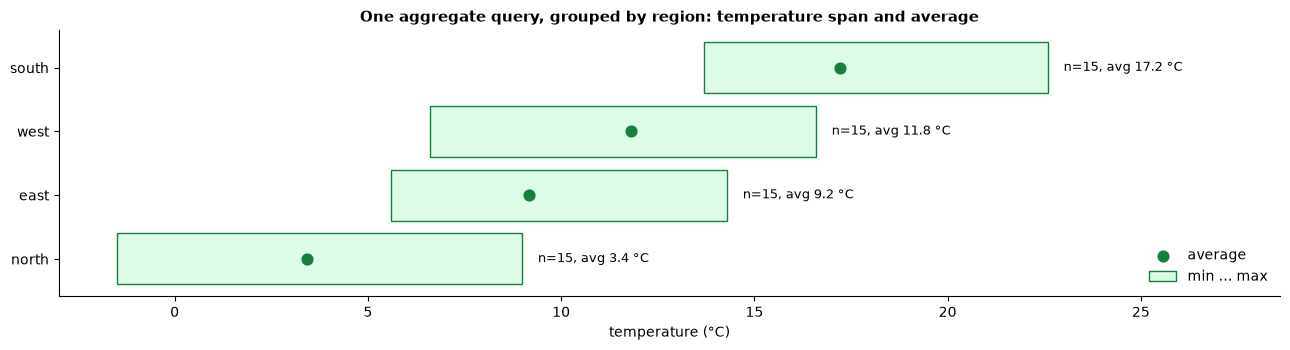

In [5]:
agg = pd.DataFrame(by_region["rows"]).set_index("region").sort_values("avg_temp")
assert agg["n"].sum() == 60
assert warm == int((data["temp"] >= 20).sum())                     # same answer as pandas

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.barh(agg.index, agg["max_temp"] - agg["min_temp"], left=agg["min_temp"], color=COLORS["B_light"],
        edgecolor=COLORS["B"], label="min … max")
ax.scatter(agg["avg_temp"], agg.index, color=COLORS["B"], zorder=3, s=60, label="average")
for region, row in agg.iterrows():
    ax.text(row["max_temp"] + 0.4, region, f"n={int(row['n'])}, avg {row['avg_temp']:.1f} °C", va="center", fontsize=9)
ax.set_xlim(agg["min_temp"].min() - 1.5, agg["max_temp"].max() + 6)
ax.set_xlabel("temperature (°C)")
ax.set_title("One aggregate query, grouped by region: temperature span and average")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**Was ist passiert?** Ein einziger Aufruf hat eine `GROUP BY`-Frage mit `count`, `avg`, `min` und
`max` beantwortet. Beachte, dass die Ergebnisse auch **Datensatznummern** tragen (`N13`, …): Jeder
Treffer bleibt mit seiner Adresse im Dynadron verbunden.

> **Detail in 0.27.1:** `order_by` in `QueryEngine.execute` wirkt nur für Felder, die auch in
> `select` aufgeführt sind (NHySQL-`ORDER BY` hat diese Einschränkung nicht).

## 4 · Scan oder Index? Frag `explain`

**Frage:** Wie beantwortet die Engine `region == "east"`?

Ohne Index liest sie alle Datensätze (`MATERIALIZED_SCAN`). Nachdem ein VALUE-Index gebaut ist,
nutzt der Planer ihn (`VALUE_INDEX`). Indizes werden nicht automatisch gepflegt: `build_indexes()`
nach dem Schreiben (Details in Notebook 08).

In [6]:
question = Q.field("region") == "east"

with nhydb.open(PATH) as db:
    before = QueryEngine(db).explain(question, realm=1)["plan"]
    db.create_index(1, 1, "by_region", "region")
    db.create_index(2, 1, "by_temp", "temp")
    db.build_indexes(commit=True)
    after = QueryEngine(db).explain(question, realm=1)["plan"]
    hits_after = QueryEngine(db).execute(question, realm=1, return_mode="count")["count"]

keys = ["access", "index_name", "estimated_rows", "estimated_cost"]
plans = pd.DataFrame([{k: before[k] for k in keys}, {k: after[k] for k in keys}],
                     index=["without index", "with VALUE index"])
assert before["access"] == "MATERIALIZED_SCAN" and after["access"] == "VALUE_INDEX"
assert hits_after == int((data["region"] == "east").sum())
plans

,access,index_name,estimated_rows,estimated_cost
without index,MATERIALIZED_SCAN,NaN,60,60.0
with VALUE index,VALUE_INDEX,by_region,15,23.0


**Was ist passiert?** Gleiche Frage, gleiche Antwort, anderer Weg: Der geschätzte Aufwand ist von
60 Datensätzen auf die 15 Index-Treffer gesunken. Bei 60 Datensätzen spielt das kaum eine Rolle;
bei Millionen ist es der Unterschied zwischen „alles lesen“ und „nur die Treffer lesen“
(Notebook 13 misst es).

## 5 · NHySQL: dieselben Fragen in SQL

**Frage:** Können wir diese Fragen in SQL schreiben?

NHySQL ist ein nur lesender `SELECT`-Dialekt. Die Quelle ist der Layoutname. Parameter sind `?`
(Liste) oder `:name` (Dict). Strukturelle Verweise wie `@u` geben Zugriff auf die Adresse.

In [7]:
with nhydb.open(PATH) as db:
    sql_count = db.sql("SELECT COUNT(*) AS n FROM observations WHERE temp >= ?", [20])["rows"][0]["n"]
    sql_groups = db.sql("SELECT region, COUNT(*) AS n, AVG(temp) AS avg_temp FROM observations "
                        "GROUP BY region ORDER BY avg_temp")["rows"]
    sql_south = db.sql("SELECT id, city, temp FROM observations "
                       "WHERE region = :r AND temp BETWEEN :lo AND :hi ORDER BY temp DESC LIMIT 5",
                       {"r": "south", "lo": 18, "hi": 30})["rows"]
    sql_struct = db.sql("SELECT id, city FROM observations WHERE @u BETWEEN 20 AND 24")["rows"]
    sql_plan = db.sql("EXPLAIN SELECT id FROM observations WHERE region = 'east'")["plan"]["access"]
    as_numpy = db.sql_numpy("SELECT temp, humidity FROM observations WHERE region = ?", ["north"])

# the SQL answers agree with the QueryEngine answers from section 3
assert sql_count == warm
assert [r["id"] for r in sql_south] == [r["id"] for r in south_warm["rows"]]
assert {r["region"]: r["n"] for r in sql_groups} == agg["n"].to_dict()
print("COUNT(*) with temp ≥ 20:", sql_count, "| EXPLAIN:", sql_plan)
print("structural @u 20–24:", [r["city"] for r in sql_struct])
print("NumPy output:", {k: (v.dtype, v.shape) for k, v in as_numpy.items()})
pd.DataFrame(sql_groups)

COUNT(*) with temp ≥ 20: 4 | EXPLAIN: VALUE_INDEX
structural @u 20–24: ['Brest', 'Porto', 'Vienna', 'Krakow', 'Sofia']
NumPy output: {'temp': (dtype('float64'), (15,)), 'humidity': (dtype('int64'), (15,))}


,region,n,avg_temp
0,north,15,3.433333
1,east,15,9.160000
2,west,15,11.820000
3,south,15,17.206667


NHySQL liest nur. Schreibende Anweisungen, `DISTINCT`, `HAVING` und Joins werden abgelehnt:

In [8]:
with nhydb.open(PATH) as db:
    for statement in ("DELETE FROM observations", "UPDATE observations SET temp = 0",
                      "SELECT DISTINCT city FROM observations"):
        try:
            db.sql(statement)
            raise AssertionError("should have failed")
        except nhydb.SQLSyntaxError as e:
            print(f"{statement:45} → SQLSyntaxError")

DELETE FROM observations                      → SQLSyntaxError
UPDATE observations SET temp = 0              → SQLSyntaxError
SELECT DISTINCT city FROM observations        → SQLSyntaxError


## 6 · Textsuche mit Relevanz

**Frage:** Welche Berichte sprechen von **starkem Wind**?

Ein FULLTEXT-Index bewertet Treffer mit **BM25** (seltene und wiederholte Wörter zählen mehr).
`CONTAINS` in SQL oder `.contains()` in `Q` findet Teilzeichenketten ohne Bewertung.

8 reports match all three words; exact phrase 'strong wind': 14 reports


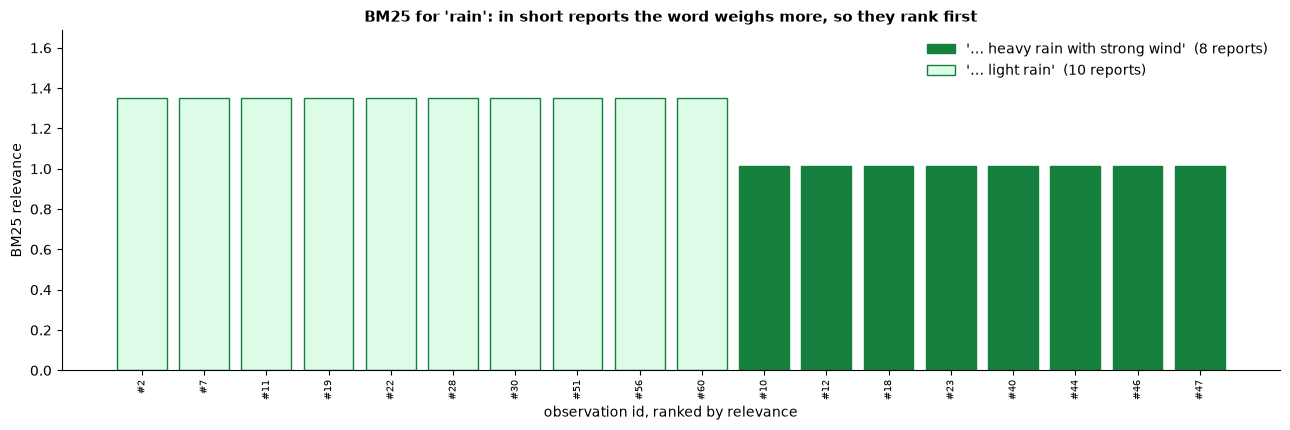

In [9]:
with nhydb.open(PATH) as db:
    db.create_fulltext_index(3, 1, "ft_report", "report")
    db.build_indexes([3], commit=True)
    q = QueryEngine(db)
    ranked = q.search(Q.fulltext("report", "strong wind rain"), realm=1, select=["id", "report"], limit=25)
    phrase = q.execute(Q.field("report").phrase("strong wind"), realm=1, return_mode="count")["count"]
    sql_rank = db.sql("SELECT id, relevance FROM observations WHERE FULLTEXT(report, :q) "
                      "ORDER BY relevance DESC LIMIT 25", {"q": "strong wind rain"})["rows"]

hits = pd.DataFrame(ranked["rows"])
assert sorted(r["id"] for r in sql_rank) == sorted(hits["id"])  # SQL and Q find the same reports
print(f"{len(hits)} reports match all three words; exact phrase 'strong wind': {phrase} reports")
with nhydb.open(PATH) as db:
    rain = QueryEngine(db).search(Q.fulltext("report", "rain"), realm=1, select=["id", "report"], limit=40)["rows"]
ranked_rain = pd.DataFrame(rain)
kinds = ranked_rain["report"].str.split(": ").str[1]
palette = {k: c for k, c in zip(sorted(set(kinds)), [COLORS["B"], COLORS["B_light"], "#86efac"])}

fig, ax = plt.subplots(figsize=(13, 4.4))
ax.bar(range(len(ranked_rain)), ranked_rain["relevance"], color=[palette[k] for k in kinds],
       edgecolor=COLORS["B"])
ax.set_xticks(range(len(ranked_rain)))
ax.set_xticklabels([f"#{i}" for i in ranked_rain["id"]], fontsize=7, rotation=90)
handles = [Rectangle((0, 0), 1, 1, facecolor=c, edgecolor=COLORS["B"]) for c in palette.values()]
ax.legend(handles, [f"'… {k}'  ({(kinds == k).sum()} reports)" for k in palette], frameon=False,
          loc="upper right")
ax.set_ylim(0, ranked_rain["relevance"].max() * 1.25)
ax.set_ylabel("BM25 relevance")
ax.set_xlabel("observation id, ranked by relevance")
ax.set_title("BM25 for 'rain': in short reports the word weighs more, so they rank first")
plt.tight_layout()
plt.show()

## 7 · Fragen über Zahlen: Math-Provider

**Frage:** Welche Datensätze liegen zwischen den Zahlen `N = 550` und `N = 560`?

Diese Frage kann keine gewöhnliche Datenbank stellen. `Q.math(provider, …)` erzeugt **Zellzahlen
aus einer Berechnung** statt aus gespeicherten Daten:

* `n_sequence` läuft durch `N = start, start+step, …, stop` und macht aus jeder Zahl ihre Zelle –
  Grenzpunkte (GZ, N0) werden **automatisch übersprungen**;
* `formula` berechnet Zellen aus Ausdrücken in `u` und `V` über einen Parameter `k`.

In [10]:
with nhydb.open(PATH) as db:
    q = QueryEngine(db)
    seq = Q.math("n_sequence", start=550, stop=560)
    as_cells = q.execute(seq, realm=1, return_mode="cell")["rows"]
    as_records = q.execute(seq, realm=1)["rows"]

cells_df = pd.DataFrame([{"N": c["N"], "u": c["u"], "v": c["v"], "lane": c["lane_name"],
                          "field": c.get("field"), "value": c.get("value")} for c in as_cells])
returned = {int(c["N"][1:]) for c in as_cells}
skipped = [n for n in range(550, 561) if n not in returned]
print("skipped by the provider:", skipped, "→", [kind_of(n) for n in skipped])
assert all(kind_of(n) in ("GZ", "N0") for n in skipped)
cells_df

skipped by the provider: [552] → ['N0']


,N,u,v,lane,field,value
0,N550,2,21,NR,v21,None
1,N551,1,22,NR,v22,None
2,N553,23,1,NL,id,23
3,N554,22,2,NL,city,Vienna
4,N555,21,3,NL,region,west
5,N556,20,4,NL,temp,9.6
6,N557,19,5,NL,humidity,71
7,N558,18,6,NL,report,Naples: heavy rain with strong wind
8,N559,17,7,NL,v7,None
9,N560,16,8,NL,v8,None


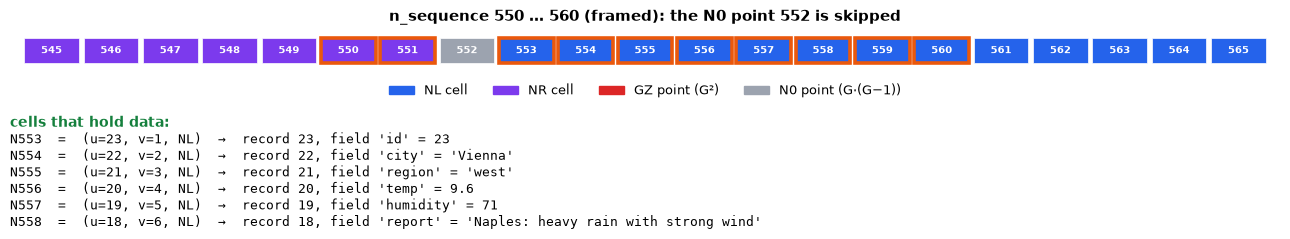

,record_N,id,city,region,temp,humidity,report
0,N5,–,–,–,–,–,–
1,N10,–,–,–,–,–,–
2,N273,16.0,Lisbon,south,21.2,84.0,Lisbon: strong wind from the sea
3,N307,17.0,Seville,south,16.8,58.0,Seville: thunderstorm in the evening
4,N343,18.0,Naples,south,16.6,79.0,Naples: heavy rain with strong wind
5,N381,19.0,Dublin,west,15.4,71.0,Dublin: light rain
6,N421,20.0,Brest,west,9.6,91.0,Brest: thunderstorm in the evening
7,N463,21.0,Porto,west,10.1,53.0,Porto: thunderstorm in the evening
8,N507,22.0,Vienna,east,10.3,42.0,Vienna: light rain
9,N553,23.0,Krakow,east,9.1,83.0,Krakow: heavy rain with strong wind


In [11]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 3.6), gridspec_kw={"height_ratios": [1, 1.1]})
plot_number_line(ax1, 545, 566, per_row=21, highlight=returned,
                 title="n_sequence 550 … 560 (framed): the N0 point 552 is skipped")
stored = [c for c in as_cells if c.get("value") is not None]
ax2.axis("off")
ax2.text(0, 0.8, "cells that hold data:", fontsize=10, fontweight="bold", color=COLORS["B"])
for i, c in enumerate(stored):
    ax2.text(0, 0.45 - 0.35 * i, f"{c['N']}  =  (u={c['u']}, v={c['v']}, {c['lane_name']})  →  record {c['u']}, "
             f"field '{c['field']}' = {c['value']!r}", fontsize=9, family="monospace")
plt.tight_layout()
plt.show()

rec_df = pd.DataFrame([{"record_N": r["record_N"], **r["data"]} for r in as_records]).fillna("–")
rec_df

**Was ist passiert? – zwei Sichten auf denselben Zahlenbereich**

* Im **Zellbereich** (`return_mode="cell"`) kommt jede Zahl des Bereichs, die eine Zelle ist, mit
  ihrer Adresse zurück – gespeichert oder nicht. Die NL-Zellen 553 … 558 liegen auf einer Diagonale
  der Gruppe 24, daher trifft jede von ihnen **ein anderes Feld einer anderen Beobachtung**
  (Datensätze 23 abwärts bis 18). Die NR-Zellen 550 und 551 und die NL-Zellen jenseits der sechs
  Felder sind leer.
* Im **Datensatzbereich** (Standard) wird jede Zelle über ihren Anker dem Datensatz zugeordnet, zu
  dem sie gehört: Das Ergebnis ist eine Liste von Datensatznummern `record_N` mit ihren Daten.
  Zellen auf Lane NR gehören zu Datensätzen, die hier keine Daten haben, deshalb ist ihr `data` leer.

**Ah – in NHyDB ist „ein Zahlenbereich“ eine sinnvolle Frage, und die Engine weiß, welche Zahlen
keine Zellen sind.**

### Der `formula`-Provider: Zellen auf einer Kurve

`formula` wertet `u` und `V` für `k = start … stop` aus. Mit `u = k, V = k` liegen die Zellen auf
der Diagonale der Adressebene – hier greifen sie je ein Feld der ersten Datensätze auf.

[('N3', 'id', 1), ('N14', 'city', 'Tromsø'), ('N33', 'region', 'north'), ('N60', 'temp', 13.7), ('N95', 'humidity', 39), ('N138', 'report', 'Naples: strong wind from the sea')]


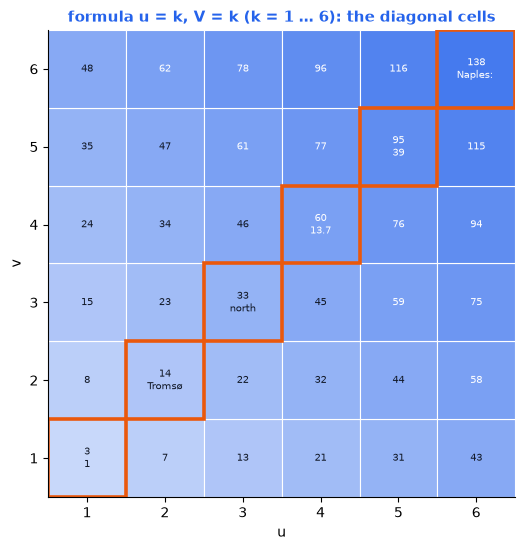

In [12]:
with nhydb.open(PATH) as db:
    diag = QueryEngine(db).execute(Q.math("formula", u="k", V="k", side="NL", start=1, stop=6),
                                   realm=1, return_mode="cell")["rows"]
values = {(c["u"], c["v"]): str(c.get("value"))[:8] for c in diag}
print([(c["N"], c.get("field"), c.get("value")) for c in diag])

fig, ax = plt.subplots(figsize=(7, 5.6))
plot_address_grid(ax, 6, 6, "NL", highlight=set(values), values=values,
                  title="formula u = k, V = k (k = 1 … 6): the diagonal cells")
plt.tight_layout()
plt.show()
assert [c["N"] for c in diag] == [f"N{nhydb.dynadron_n(1, k, k, 'NL')}" for k in range(1, 7)]

## 8 · ▶ Dein eigenes SQL

**Ändere es:** Schreibe ein beliebiges `SELECT` über das Layout `observations` (Felder `id`, `city`,
`region`, `temp`, `humidity`, `report`).

In [13]:
# ▶ Try it: change the query and re-run
MY_SQL = "SELECT city, COUNT(*) AS n, MAX(temp) AS hottest FROM observations WHERE humidity > ? GROUP BY city ORDER BY hottest DESC LIMIT 6"
MY_PARAMS = [60]

with nhydb.open(PATH) as db:
    result = db.sql(MY_SQL, MY_PARAMS)
pd.DataFrame(result["rows"], columns=result["columns"])

,city,n,hottest
0,Lisbon,3,22.6
1,Seville,3,18.2
2,Naples,3,18.0
3,Dublin,4,15.9
4,Porto,2,13.9
5,Krakow,4,10.6


## Jetzt du

**Aufgabe:** Wie hoch ist die Durchschnittstemperatur der **nördlichen** Beobachtungen, die **über
0 °C** liegen? Beantworte es einmal mit `Q` und einmal mit SQL und vergleiche mit pandas.

In [14]:
with nhydb.open(PATH) as db:
    by_q = QueryEngine(db).execute((Q.field("region") == "north") & (Q.field("temp") > 0), realm=1,
                                   aggregate={"avg": ("avg", "temp")})["rows"][0]["avg"]
    by_sql = db.sql("SELECT AVG(temp) AS avg FROM observations WHERE region = 'north' AND temp > 0")["rows"][0]["avg"]
by_pandas = data[(data["region"] == "north") & (data["temp"] > 0)]["temp"].mean()
print(f"Q: {by_q:.3f}   SQL: {by_sql:.3f}   pandas: {by_pandas:.3f}")
assert abs(by_q - by_pandas) < 1e-9 and abs(by_sql - by_pandas) < 1e-9

Q: 5.560   SQL: 5.560   pandas: 5.560


## ⏩ Vertiefung: Abfragen als Daten

Für Konfigurationsdateien oder Web-APIs kann eine Abfrage ein einfaches Dictionary sein:
`execute_spec` führt es aus, `expr_from_spec` macht daraus einen `Q`-Ausdruck.

In [15]:
spec = {"where": {"field": "humidity", "op": "ge", "value": 90}, "realm": 1, "return": "count"}
with nhydb.open(PATH) as db:
    q = QueryEngine(db)
    n_spec = q.execute_spec(spec)["count"]
    expr = expr_from_spec({"field": "humidity", "op": "ge", "value": 90})
    n_expr = q.execute(expr, realm=1, return_mode="count")["count"]
print(expr, "→", n_spec)
assert n_spec == n_expr == int((data["humidity"] >= 90).sum())

FieldPredicate(name='humidity', op='ge', value=90, value2=None, options={}) → 5


## Zusammenfassung

* Wenn du die Adresse kennst, brauchst du keine Abfrage: `get`, `range`, `select`, `get_n`.
* Die QueryEngine (`Q`) und NHySQL teilen sich einen Planer; Filter, Gruppen, Aggregate und BM25-Suche funktionieren in beiden.
* `explain` zeigt, ob ein Scan oder ein Index eine Frage beantwortet; Indizes werden ausdrücklich gebaut.
* NHySQL ist nur lesend; Ergebnisse können als Dictionaries, Datensatznummern oder NumPy-Arrays zurückkommen.
* Math-Provider stellen Fragen über **Zahlen**: `n_sequence` überspringt GZ/N0 automatisch, `formula` folgt einer Kurve.

## Wie es weitergeht

* [08 · Adressen sind keine Suchindizes](08_addresses_are_not_indexes_v1.ipynb) – Indexfamilien und Aktualität.
* [10 · NumPy-Batches](10_numpy_batches_v1.ipynb) – Massendaten hinein und heraus.
* [13 · Benchmark-Labor](13_benchmark_lab_v1.ipynb) – Scan gegen Index, gemessen.

**Cookbook-Abschnitte:** 12 (Bereiche und Iteratoren), 13 (Sekundärindizes), 14 (QueryEngine), 15 (NHySQL) im [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [16]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
